## Import modules

In [87]:
import numpy as np
import pandas as pd
from reactionmodel.model import Species, ReactionRateFamily
from reactionmodel.hook import HookAwareModel
import reactionmodel.parser as parser

## Load arrows from the excel document

In [88]:
def concatenate_columns(df, columns, parentheses=True, sep='*', na_rep=None):
    df = df[columns].copy()
    if parentheses:
        df['left'] = '('
        df['right'] = ')'
    else:
        df['left'] = ''
        df['right'] = ''
    for c in columns:
        df[c] = df['left'].str.cat(df[c]).str.cat(df['right'])
    
    first_col = df[columns[0]]
    later_cols = df[columns[1:]]
    return first_col.str.cat(later_cols, sep=sep, na_rep=na_rep)

In [89]:
arrows_file = pd.ExcelFile('./Shared model arrows.xlsx')
arrows = arrows_file.parse('Reactions').drop(0)
arrows = arrows[arrows['Include'].astype(bool)]
arrows['Initial'] = arrows['Initial (A)'].str.cat(arrows['Initial (N)'], sep='_')
arrows['Final'] = arrows['Final (A)'].str.cat(arrows['Final (N)'], sep='_')

arrows['Initial'] = arrows['Initial'].str.replace('-_-', '')
arrows['Final'] = arrows['Final'].str.replace('-_-', '')
# It's dumb, but k stem is guaranteed non-blank where Description (ie not Description stem) is guaranteed non-blank
arrows['k'] = concatenate_columns(arrows, ['k stem', 'k']).fillna(arrows['k stem'])
arrows['Description'] = concatenate_columns(arrows, ['Description stem', 'Description'], sep=' ', parentheses=False).fillna(arrows['Description'])

arrows = arrows[['Group', 'Description', 'Initial', 'Final', 'k', 'trigger']]

arrows

,Group,Description,Initial,Final,k,trigger
1,Colonization,"Colonization of ""healthy"" host by DS without i...",M_M,M_DS,(beta * (1 - CR_N) * (1 - p_beta_infection_M) ...,NaN
2,Colonization,"Colonization of ""healthy"" host by DS with inst...",M_M,DS_DS,(beta * (1 - CR_N) * (p_beta_infection_M) * PR...,NaN
3,Colonization,"Colonization of ""healthy"" host by DR without i...",M_M,M_DR,(beta * (1 - CR_N) * (1 - p_beta_infection_M) ...,NaN
4,Colonization,"Colonization of ""healthy"" host by DR with inst...",M_M,DR_DR,(beta * (1 - CR_N) * (p_beta_infection_M) * PR...,NaN
5,Colonization,Colonization of low dysbiosis host by DS witho...,M_X,M_DS,(beta * (1 - p_beta_infection_M) * PRESSURE_DS...,NaN
...,...,...,...,...,...,...
71,Treatment brick 1,Action: <DR || Extent: failure,DR_DR,DR_DR,(tau)*(p_extent_failure * (p_action_DSDR) + (1...,NaN
72,Treatment brick 1,Action: >=DR. Extent: eradicating,DR_DSDR,X_X,(tau)*(p_action_DSDR * p_extent_eradicating),NaN
74,Treatment brick 1,Action: >=DR. Extent: non-eradicating,DR_DSDR,X_DSDR,(tau)*(p_action_DSDR * p_extent_non_eradicating),NaN
76,Treatment brick 1,(Action: >=DS <DR && Extent: non-eradicating),DR_DSDR,DR_DSDR,(tau)*((p_action_DS * p_extent_non_eradicating)),NaN


In [90]:
hooks = arrows_file.parse('Hooks').set_index('Triggering group')
hooks

,Triggered group
Triggering group,
Discharge,Admission


## Parse file into a Model

In [91]:
# PROBLEM: DSDR can't exist in high abundance
families = {
    'star': ['M', 'X', 'DS', 'DR', 'DSDR']
}

In [92]:
def parse_arrow(arrow):
    family_flag = False

    if pd.isna(arrow.trigger):
        arrow_dictionary = {'k': arrow.k}
    else:
        arrow_dictionary = {'p': arrow.k}

    reactants = arrow.Initial
    if reactants.count('*') > 1: assert False
    elif reactants.count('*') == 1: family_flag = True
    reactants = reactants.replace('*', '$i')

    products = arrow.Final
    if products.count('*') > 1: assert False
    elif products.count('*') == 1: family_flag = True
    products = products.replace('*', '$i')

    reactants = [reactants] if reactants else []
    products = [products] if products else []

    arrow_dictionary.update({
        'description': arrow.Description,
        'reactants': reactants,
        'products': products,
    })

    if arrow.Group in hooks.index:
        arrow_dictionary['hooked_set'] = hooks.loc[arrow.Group]['Triggered group']

    if family_flag:
        arrow_dictionary['used_families'] = {'i': 'star'}

    return arrow_dictionary

In [93]:
from collections import defaultdict
reactions = []
hooked_sets = defaultdict(lambda: [])

# collect triggered reactions first
for i, arrow in arrows.iterrows():
    if pd.isna(arrow.trigger):
        continue

    arrow_dictionary = parse_arrow(arrow)
    hooked_sets[arrow.Group].append(arrow_dictionary)


for i, arrow in arrows.iterrows():
    if not pd.isna(arrow.trigger):
        continue

    arrow_dictionary = parse_arrow(arrow)
    reactions.append(arrow_dictionary)

In [94]:
species_df = arrows_file.parse('Species')
base_species = [Species(s.Name, description=s.Description) for _,s in species_df.fillna('').iterrows()]

bad_species = [
    {'name':'DS_M'},
    {'name':'DS_X'},
    {'name':'DS_DR'},
    {'name':'DR_M'},
    {'name':'DR_X'},
    {'name':'DR_DS'},
    {'name':'X_M'},
    {'name':'DSDR_DSDR'},
    {'name':'DSDR_DS'},
    {'name':'DSDR_DR'},
]
bad_species = [Species(**s) for s in bad_species]

species = [s.to_dict() for s in base_species] + [s.to_dict() for s in bad_species]

In [95]:
model_dictionary = {
    'families': families,
    'species': species,
    'reactions': reactions,
    'triggered_sets': hooked_sets
}

results = parser.loads(model_dictionary, model_class=HookAwareModel)

In [96]:
filtered_reactions = [r for r in results.model.all_reactions if not set(r.reactants).intersection(bad_species) and not set(r.products).intersection(bad_species)]

In [97]:
filtered_model = HookAwareModel(
    base_species,
    [r for r in results.model.all_reactions if not set(r.reactants).intersection(bad_species) and not set(r.products).intersection(bad_species)]
)

In [98]:
parameters = arrows_file.parse('Parameters')[['Parameter', 'Value']].set_index('Parameter').to_dict()['Value']
## At some point here evaluate the rate constants at the parameters

needs_pressure_ds = [i for i,r in enumerate(filtered_model.all_reactions) if 'PRESSURE_DS' in r.k]
needs_pressure_dr = [i for i,r in enumerate(filtered_model.all_reactions) if 'PRESSURE_DR' in r.k]

parameters.update({'PRESSURE_DS': 1, 'PRESSURE_DR': 1})

all_k = filtered_model.get_k(parameters=parameters)
assert(isinstance(all_k, np.ndarray))

Evaluating expression: (beta * (1 - CR_N) * (1 - p_beta_infection_M) * PRESSURE_DS)*((1 - CR_A)) => 0.019000000000000003
Evaluating expression: (beta * (1 - CR_N) * (p_beta_infection_M) * PRESSURE_DS )*((1 - CR_A)) => 0.0010000000000000002
Evaluating expression: (beta * (1 - CR_N) * (1 - p_beta_infection_M) * PRESSURE_DR)*((1 - CR_A)) => 0.019000000000000003
Evaluating expression: (beta * (1 - CR_N) * (p_beta_infection_M) * PRESSURE_DR)*((1 - CR_A)) => 0.0010000000000000002
Evaluating expression: (beta * (1 - p_beta_infection_M) * PRESSURE_DS)*((1 - CR_A)) => 0.02375
Evaluating expression: (beta * (p_beta_infection_M) * PRESSURE_DS)*((1 - CR_A)) => 0.0012500000000000002
Evaluating expression: (beta * (1 - p_beta_infection_M) * PRESSURE_DR)*((1 - CR_A)) => 0.02375
Evaluating expression: (beta * (p_beta_infection_M) * PRESSURE_DR)*((1 - CR_A)) => 0.0012500000000000002
Evaluating expression: beta * (1 - p_beta_infection_X) * PRESSURE_DS => 0.04000000000000001
Evaluating expression: beta *

In [99]:
import numpy as np
from reactionmodel.model import eval_expression

s_df = species_df.set_index('Name')
pressure_ds_vec = np.zeros(len(filtered_model.species))
pressure_dr_vec = np.zeros(len(filtered_model.species))

for i,s in enumerate(filtered_model.species):
    pressure_ds_vec[i] = eval_expression(str(s_df.loc[s.name]['PRESSURE_DS']), parameters)
    pressure_dr_vec[i] = eval_expression(str(s_df.loc[s.name]['PRESSURE_DR']), parameters)

Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: psi_colonization => 0.01
Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: psi_colonization => 0.01
Evaluating expression: 1/2 * psi_colonization => 0.005
Evaluating expression: 1/2 * psi_colonization => 0.005
Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: psi_colonization => 0.01
Evaluating expression: 0 => 0.0
Evaluating expression: 0 => 0.0
Evaluating expression: psi_colonization => 0.01
Evaluating expression: 1/2 * psi_colonization => 0.005
Evaluating expression: 1/2 * psi_colonization => 0.005
Evaluating expression: 1 => 1.0
Evaluating expression: 0 => 0.0
Evaluating expression: 1-(1/2*psi_colonization) => 0.995
Evaluating expression: 1/2 * psi_colonization => 0.005
Evaluating expression: 0 => 0.0
Evaluating expression: 1 => 1.0
Evaluating expression: 1/2 *

# Install parameters

In [100]:
N = 250
parameters['beta'] = parameters['beta'] / N

In [101]:
from numba import jit as numbajit

parametrized_reactions = []
for i,rxn in enumerate(filtered_model.all_reactions):
    k = all_k[i]
    if i in needs_pressure_ds:
        assert i not in needs_pressure_dr
        @numbajit(nopython=True)
        def pressure_ds(t, y):
            pressure = np.zeros(1)
            pressure[0] = np.sum(y * pressure_ds_vec)
            return pressure
        k = pressure_ds
    elif i in needs_pressure_dr:
        assert i not in needs_pressure_ds
        @numbajit(nopython=True)
        def pressure_dr(t, y):
            pressure = np.zeros(1)
            pressure[0] = np.sum(y * pressure_dr_vec)
            return pressure
        k = pressure_dr
    existing_dict = rxn.to_dict(keep_species_objects=True)
    existing_dict.update({'k': k})
    parametrized_reactions.append(type(rxn)(**existing_dict))

In [102]:
np.sum(np.zeros(len(filtered_model.species)) * pressure_dr_vec, keepdims=True)

array([0.])

In [103]:
parametrized_reactions = [r for r in parametrized_reactions if r.k != 0]

In [104]:
parametrized_model = HookAwareModel(
    base_species,
    parametrized_reactions
)

# Gillespie

In [105]:
i_to_partition = {}
for i,label in enumerate(parametrized_model.legend()):
    if 'DS_' in label:
        partition = 'susceptible infection'
    elif 'DR_' in label:
        partition = 'resistant infection'
    elif '_DSDR' in label:
        partition = 'dual colonization'
    elif '_DS' in label:
        partition = 'DS colonization'
    elif '_DR' in label:
        partition = 'DR colonization'
    else:
        partition = 'uninfected uncolonized'
    i_to_partition[i] = partition

def sum_and_relabel(m, state):
    partition_to_amount = {}
    for i,x in enumerate(state):
        try:
            partition_to_amount[i_to_partition[i]] += x
        except KeyError:
            partition_to_amount[i_to_partition[i]] = x
    
    return partition_to_amount

In [106]:
from hybrid.gillespie import GillespieSimulator
s = GillespieSimulator.from_model(parametrized_model, parameters=parameters, jit=False)

Evaluating expression: ((1 - p_admitted_infected) * (1 - p_colonized))*((1 - p_high_dysbiosis - p_low_dysbiosis)) => 0.5
Evaluating expression: ((1 - p_admitted_infected) * (1 - p_colonized))*(p_low_dysbiosis) => 0.2
Evaluating expression: ((1 - p_admitted_infected) * (1 - p_colonized))*(p_high_dysbiosis) => 0.1
Evaluating expression: ((1 - p_admitted_infected) * (1 - p_high_dysbiosis) * p_colonized)*(f_S) => 0.14
Evaluating expression: ((1 - p_admitted_infected) * (1 - p_high_dysbiosis) * p_colonized)*(f_R) => 0.019250000000000003
Evaluating expression: ((1 - p_admitted_infected) * (1 - p_high_dysbiosis) * p_colonized)*(f_dual) => 0.01575
Evaluating expression: ((1 - p_admitted_infected) * (p_high_dysbiosis) * p_colonized)*(f_S) => 0.020000000000000004
Evaluating expression: ((1 - p_admitted_infected) * (p_high_dysbiosis) * p_colonized)*(f_R) => 0.0027500000000000003
Evaluating expression: ((1 - p_admitted_infected) * (p_high_dysbiosis) * p_colonized)*(f_dual) => 0.00225
Evaluating ex

In [107]:
initial = parametrized_model.make_initial_condition({'M_M': N*0.8, 'M_DS': N*0.15, 'M_DR': N*0.05})

In [108]:
result = s.simulate([0, 1.0], initial, np.random.default_rng())

<Axes: >

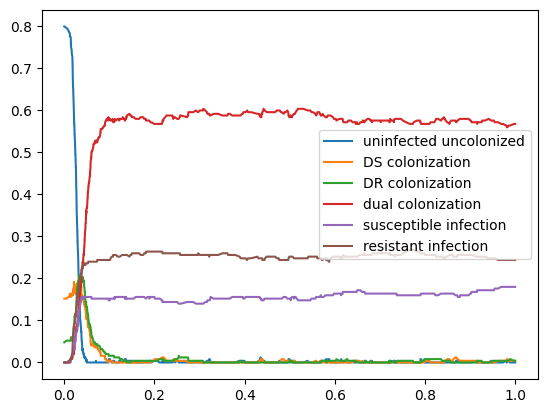

In [109]:
# Use the sum_and_relabel tool on point in the history
new_y = []
for y in result.y_history.T:
    new_y.append(sum_and_relabel(parametrized_model, y))

# Make a dataframe of the results
# A Pandas DataFrame is designed to match R dataframes, so hopefully it will be somewhat familiar 
df = pd.DataFrame(new_y, index=result.t_history)

(df / N).plot()

In [63]:
df

,uninfected uncolonized,DS colonization,DR colonization,dual colonization,susceptible infection,resistant infection
0,200.0,38.0,12.0,0.0,0.0,0.0
1,199.0,38.0,12.0,0.0,0.0,1.0
2,198.0,38.0,12.0,0.0,1.0,1.0
3,197.0,38.0,13.0,0.0,1.0,1.0
4,197.0,38.0,13.0,0.0,1.0,1.0
...,...,...,...,...,...,...
882,0.0,1.0,2.0,130.0,18.0,99.0
883,0.0,1.0,2.0,130.0,18.0,99.0
884,1.0,1.0,2.0,130.0,17.0,99.0
885,1.0,0.0,2.0,131.0,17.0,99.0


In [62]:
result.y_history.T

array([[200.,   0.,  38., ...,   0.,   0.,   0.],
       [199.,   0.,  38., ...,   0.,   1.,   0.],
       [198.,   0.,  38., ...,   0.,   1.,   0.],
       ...,
       [  1.,   0.,   1., ...,  17.,   1.,  98.],
       [  1.,   0.,   0., ...,  17.,   1.,  98.],
       [  1.,   0.,   0., ...,  17.,   1.,  98.]])

In [59]:
df.sum(axis=1)

0      250.0
1      250.0
2      250.0
3      250.0
4      250.0
       ...  
882    250.0
883    250.0
884    250.0
885    250.0
886    250.0
Length: 887, dtype: float64

In [60]:
[s.pathway_labels[i] for i in result.pathway_history]

['~ (Action: >=DS <DR && Extent: non-eradicating) && ((Action: <DS) || (Extent: failure)',
 'Colonization of "healthy" host by DR with instant infection',
 'Colonization of "healthy" host by DS with instant infection',
 'Colonization of "healthy" host by DR without instant infection',
 'Spontaneous low dysbiosis',
 'Colonization of "healthy" host by DR without instant infection',
 'Colonization of "healthy" host by DS without instant infection',
 'Colonization of "healthy" host by DS without instant infection',
 'Colonization of "healthy" host by DS with instant infection',
 'Colonization of "healthy" host by DS with instant infection',
 'Colonization of "healthy" host by DR with instant infection',
 'Colonization of "healthy" host by DR with instant infection',
 'Colonization of "healthy" host by DR with instant infection',
 'Colonization of "healthy" host by DS without instant infection',
 'Colonization of "healthy" host by DR without instant infection',
 'Colonization of "healthy" h

In [61]:
parametrized_model.all_reactions

[ReactionWithHooks(reactants=(Species(name='M_M', description=''),), products=(Species(name='M_DS', description=''),), description='Colonization of "healthy" host by DS without instant infection', reversible=False, kinetic_orders=(Species(name='M_M', description=''),), k=CPUDispatcher(<function pressure_ds at 0x293496ca0>), hooked_reactions=None, hooked_p=None),
 ReactionWithHooks(reactants=(Species(name='M_M', description=''),), products=(Species(name='DS_DS', description=''),), description='Colonization of "healthy" host by DS with instant infection', reversible=False, kinetic_orders=(Species(name='M_M', description=''),), k=CPUDispatcher(<function pressure_ds at 0x293496d30>), hooked_reactions=None, hooked_p=None),
 ReactionWithHooks(reactants=(Species(name='M_M', description=''),), products=(Species(name='M_DR', description=''),), description='Colonization of "healthy" host by DR without instant infection', reversible=False, kinetic_orders=(Species(name='M_M', description=''),), k=